In [1]:
#############################################
## MATPLOTLIB FEATURES
%matplotlib inline
import matplotlib 
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20, labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
colors = ['black'  ,'darkgrey', '#0000ff', '#ff0000', '#0000FF',   '#FF0000', '#069AF3', 
          '#00008B','#C79FEF' , '#DC143C', '#C875C4', '#9A0EEA','darkorange', '#C79FEF',
          '#7E1E9C','silver'  , '#FF7F50', '#FC5A50', '#FFA500',   '#F97306', '#FFD700',
          '#DDA0DD','#00008B' , '#069AF3', '#0000FF', '#00FFFF',   '#13EAC9', '#7FFFD4',
          '#04D8B2','#40E0D0']
my_cmap = ListedColormap(colors, name="my_cmap")
font_dict = {'family': 'serif', 'color':  None,  'weight': 'bold','size': 30}
#############################################
import os,sys,time,camb
import healpy as hp
import numpy as np
from copy import deepcopy as dcopy
from camb import model, initialpower
from scipy import interpolate
from scipy import integrate
#############################################
import warnings
warnings.filterwarnings("ignore")
#############################################
#PATH TO SCRIPTS FOLDER
path = '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory as cxft

In [2]:
def load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=None):
    import yaml
    if survey_name.upper()=='LSST':
        path_file = '/data/AMARINS/LSSxHI-CODES/scripts/parameters/lsst_desc_parameters.yaml' \
                   if type(path_file)==type(None) else path_file
        load_pars = yaml.safe_load(open(path_file))
        if type_field.lower() in ['galaxy', 'density', 'dens', 'source', 'overdensity', 'count', 'counting']:   
            return load_pars['source_sample'][data_release.upper()] #data['source_sample'][data_release]
        if type_field.lower() in ['lensing','lens', 'shear']: 
            return load_pars['lens_sample'  ][data_release.upper()]    
    if survey_name.upper()=='EUCLID':
        path_file = '/data/AMARINS/LSSxHI-CODES/scripts/parameters/euclid_parameters.yaml' \
                   if type(path_file)==type(None) else path_file
        load_pars = yaml.safe_load(open(path_file))
        if type_field.lower() in ['galaxy', 'density', 'dens', 'source', 'overdensity', 'count', 'counting']:   
            return load_pars['source_sample']['Y10'] #data['source_sample'][data_release]
        if type_field.lower() in ['lensing','lens', 'shear']: 
            dt = load_pars['lens_sample'][data_release.upper()]  
            dt['bin_range'] = np.asarray(dt['bin_range'])
            dt['z_edges']   = np.asarray(dt['z_edges'])
            return dt
    

In [ ]:
params = { 'H0'   : 67.5,
           'ombh2': 0.022,
           'omch2': 0.122,
           'ns'   : 0.965,
           'z'    : np.logspace(np.log10(1e-10),np.log10(1150), 150),
           'kmax' : 100,
           'minkh': 1e-4,
           'maxkh': 100,
           'npoints': 1e8,
           'nonlinear':True,
           'halofit_version':'mead2020'}       


#pars = camb.CAMBparams()
cpars = camb.set_params(halofit_version=params['halofit_version'])#, HMCode_A_baryon=3.13, HMCode_eta_baryon=0.603, HMCode_logT_AGN=7.8)
                       #H0=params['H0'], ombh2=params['ombh2'], omch2=params['omch2'])
cpars.set_cosmology(H0=params['H0'], ombh2=params['ombh2'], omch2=params['omch2'])
cpars.InitPower.set_params(ns=params['ns'])
cpars.set_matter_power(redshifts=params['z'], kmax=params['kmax'])
#pars.NonLinear = model.NonLinear_both
#results.calc_power_spectra(pars)
cresults  = camb.get_results(cpars)
pk_interp = camb.get_matter_power_interpolator(cpars, 
                                               nonlinear=params['nonlinear'], hubble_units=False, k_hunit=False, 
                                               kmax=params['kmax'], zmax=params['z'][-1])
cresults.z_input = params['z']
print("done.")

Note: redshifts have been re-sorted (earliest first)


In [ ]:
path_lsst = "/data/AMARINS/CMBWLxHI-CODES/scripts/parameters/lsst_desc_parameters.yaml"

In [5]:
dens_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density',path_file=path_lsst)
dNdz_densY10_all  = cxft.dNdz_func(pars=dens_pars, binning=False ,  verbose=False, type_field=dens_pars['field'])
dNdz_densY10_bins = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

In [6]:
dens_pars = cxft.load_survey_parameters(path_file='/data/AMARINS/CMBWLxHI-CODES/scripts/parameters/lsst_desc_parameters.yaml')
zrange  = np.linspace(0.001,3.5, 500)
nz      = np.array([ cxft.nz_spec(pars=dens_pars)(ix) for ix in zrange ])
nz_bins = cxft.source_bins_lsst(redshift_range=zrange, redshift_distribution=nz, dens_pars=dens_pars)

In [7]:
path_lsst = "/data/AMARINS/CMBWLxHI-CODES/scripts/parameters/lsst_desc_parameters.yaml"
path_ecl = "/data/AMARINS/CMBWLxHI-CODES/scripts/parameters/euclid_parameters.yaml"

dens_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y1', type_field='density',path_file=path_lsst)
dNdz_densY1_all  = cxft.dNdz_func(pars=dens_pars, binning=False,  verbose=False, type_field=dens_pars['field'])
dNdz_densY1_bins = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

dens_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density',path_file=path_lsst)
dNdz_densY10_all  = cxft.dNdz_func(pars=dens_pars, binning=False ,  verbose=False, type_field=dens_pars['field'])
dNdz_densY10_bins = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

dens_pars = cxft.load_survey_parameters(survey_name ='EUCLID', data_release='Y10', type_field='density',path_file=path_ecl)
dNdz_ecl_all  = cxft.dNdz_func(pars=dens_pars, binning=False,  verbose=False, type_field=dens_pars['field'])
dNdz_ecl_bins = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

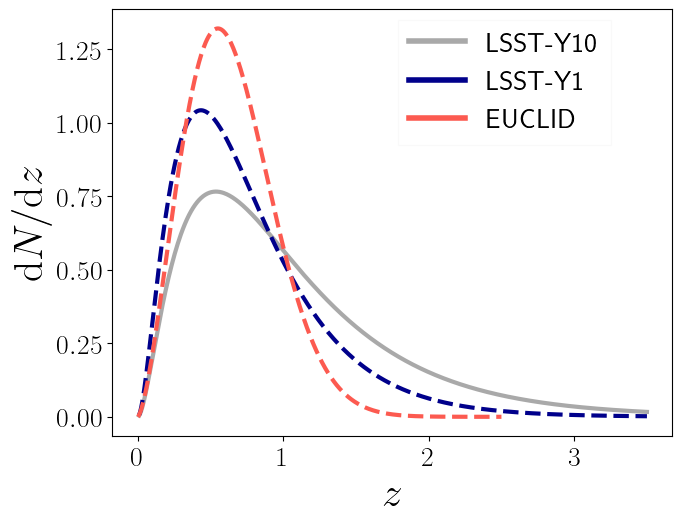

In [8]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.,right=1,wspace=0.3, hspace=0.0)
ax    = plt.subplot(grid[0,0])                  
ax.plot(dNdz_densY10_all['z'], dNdz_densY10_all['dNdz'], color=my_cmap(1), ls='solid',lw=3)
ax.plot(dNdz_densY1_all['z'] , dNdz_densY1_all['dNdz' ], color=my_cmap(7)     , ls='dashed',lw=3)
ax.plot(dNdz_ecl_all['z'] , dNdz_ecl_all['dNdz' ]      , color=my_cmap(17)     , ls='dashed',lw=3)
ax.set_xlabel(r"$z$"               , fontsize =30)
ax.set_ylabel(r"$\textrm{d}N/\textrm{d}z$", fontsize =30)    
###########################################################
custom_lines = [Line2D([], [], color=my_cmap(1)  , linewidth=4, linestyle='solid'),
                Line2D([], [], color=my_cmap(7)  , linewidth=4, linestyle='solid'),
                Line2D([], [], color=my_cmap(17)  , linewidth=4, linestyle='solid'),]
legend = ax.legend(custom_lines, [r'LSST-Y10', r'LSST-Y1', r'EUCLID'],#title='LSST',
                   ncols=1, fontsize=20, loc='lower center',framealpha=0.1, fancybox=False,
                   bbox_to_anchor=(0.70, 0.65),  shadow=False,)#edgecolor='lightblue', 
plt.setp(legend.get_title(), fontsize='24', color='black', fontweight='bold');

In [9]:
################        
def dNdz_func(pars=None, binning=False, verbose=False, type_field='lensing'):
    from scipy.interpolate import CubicSpline
    from scipy import integrate
    if verbose: timei = time.time()
    z_min,z_max = pars['z_min'], pars['z_max']
    zrange      = np.linspace(z_min, z_max, 500)
    #dNdz_vec    = np.array([ cxft.nz_spec(pars=pars)(ix) for ix in zrange ])
    #EUCLID
    nch   = pars['nbins']
    zbins = pars['bin_range']  
    for i in range(nch):
        zi_min, zi_max = zbins[i], zbins[i+1]
        idNdz      = np.array([ integrate.quad(lambda izp: cxft.nz_convolved(zp=izp,pars=pars)(iz), zi_min, zi_max)[0] for iz in zrange ])
        idNdz_intp = CubicSpline(zrange, idNdz)    
        idNdz      = idNdz/integrate.quad(lambda iz : idNdz_intp(iz), z_min, z_max)[0]
        if not i: dNdz_vec = dcopy(idNdz)
        else: dNdz_vec = np.vstack(( dNdz_vec, dcopy(idNdz) )) 
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei)) 
    return {'dNdz':dNdz_vec, 'z':zrange}

In [10]:
dens_pars = cxft.load_survey_parameters(survey_name ='EUCLID', data_release='Y10', type_field='density', path_file=path_ecl)
dNdz_ecl_bins = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

''

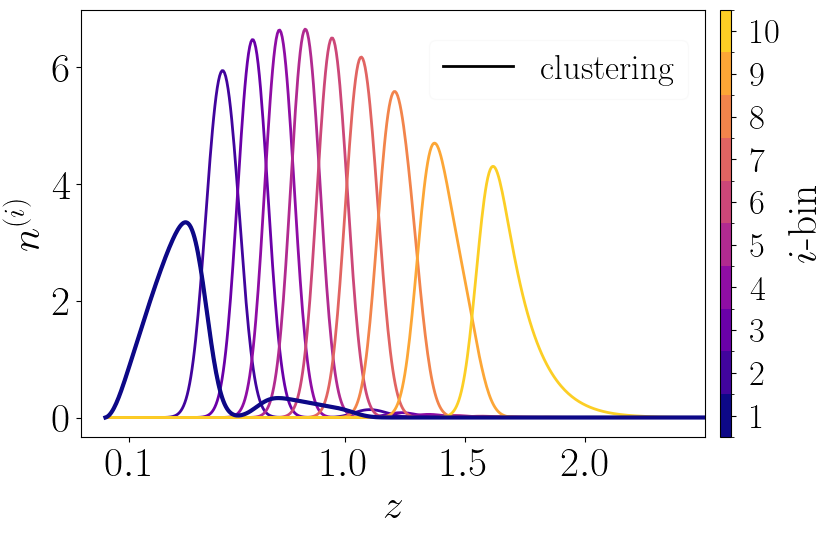

In [11]:
ncols,nrows = 1,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(1.3)*ncols, wspace=0.02, hspace=0.25)
############################################################
nch_ecl,N  = dNdz_ecl_bins['dNdz' ].shape[0], 10
c    = np.arange(1., nch_ecl + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap2 = plt.get_cmap("plasma", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap2)
sm.set_array([])
############################################################
ax1 = axes#[0]
for i in range(nch_ecl): ax1.plot(dNdz_ecl_bins[ 'z'], dNdz_ecl_bins[ 'dNdz'][i,:], c=cmap2(i), lw=2, ls='solid')
i=0;ax1.plot(dNdz_ecl_bins[ 'z'], dNdz_ecl_bins[ 'dNdz'][i,:], c=cmap2(i), lw=3, ls='solid')
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$n^{(i)}$", fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)

cxticks = [0.1,1.0,1.5,2.0]#,3.0]
ax1.set_xticks(cxticks)
ax1.set_xlim(-0.1,2.5)
###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid')]
legend_1= ax1.legend(custom_lines, [r'$\textrm{clustering}$'],
                    bbox_to_anchor=(1.0, 0.75),
                    fontsize=25,ncols=1,loc='lower right',framealpha=0.1)
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,pad=0.02, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10)
;

''

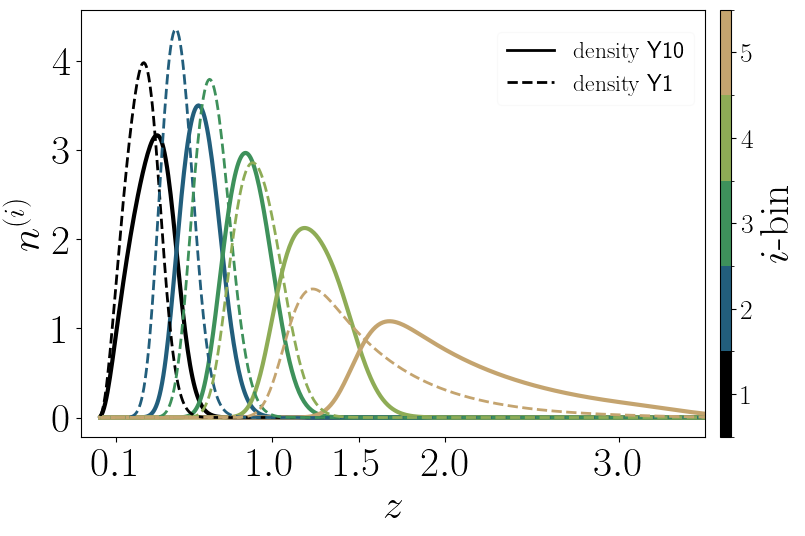

In [12]:
ncols,nrows = 1,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(1.3)*ncols, wspace=0.02, hspace=0.25)
############################################################
nch_y01  = dNdz_densY1_bins['dNdz' ].shape[0]
nch_y10  = dNdz_densY10_bins['dNdz' ].shape[0]
nch_ecl  = dNdz_ecl_bins['dNdz' ].shape[0]
#nch_euc  = nz_ecl[ 'dNdz'].shape[0]
N=5
c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

#N=10
#c    = np.arange(1., nch_ecl + 1)
#norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
#cmap2 = plt.get_cmap("plasma", N+1)
#sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap2)
#sm.set_array([])

############################################################
ax1 = axes#[0]
#
yr,yr2 = 'Y1','Y10'
#for i in range(nch_ecl): ax1.plot(dNdz_ecl_bins[ 'z'], dNdz_ecl_bins[ 'dNdz'][i,:], c=cmap2(i), lw=2, ls='solid')
for i in range(nch_y10): ax1.plot(dNdz_densY10_bins['z'], dNdz_densY10_bins['dNdz'][i,:], c=cmap(i), lw=3, ls='solid')
for i in range(nch_y01): ax1.plot(dNdz_densY1_bins[ 'z'], dNdz_densY1_bins[ 'dNdz'][i,:], c=cmap(i), lw=2, ls='dashed')
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$n^{(i)}$", fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)

#ax1.set_ylim(0,4.9)
#cyticks = np.arange(0,5.5,1.5)
#ax1.set_yticks(cyticks)
cxticks = [0.1,1.0,1.5,2.0,3.0]
ax1.set_xticks(cxticks)
ax1.set_xlim(-0.1,3.5)
#ax1.text(x=-0.05, y=4.5, s=r'$\textbf{LSST}$', 
#        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
                Line2D([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$\textrm{density}$ '+'{}'.format(yr2),
                                   r'$\textrm{density}$ '+'{}'.format(yr)],
                    bbox_to_anchor=(1.0, 0.75),
                    fontsize=17,ncols=1,loc='lower right',framealpha=0.1)
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,#es.ravel().tolist(),orientation='horizontal',# extend="both",
                  pad=0.02, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
#cbar.ax.tick_params(labelsize=25, pad=10)
;

'/data/AMARINS/LSSxHI-CODES/images/dNdz_denmsity_LSST_EUCLID.png'

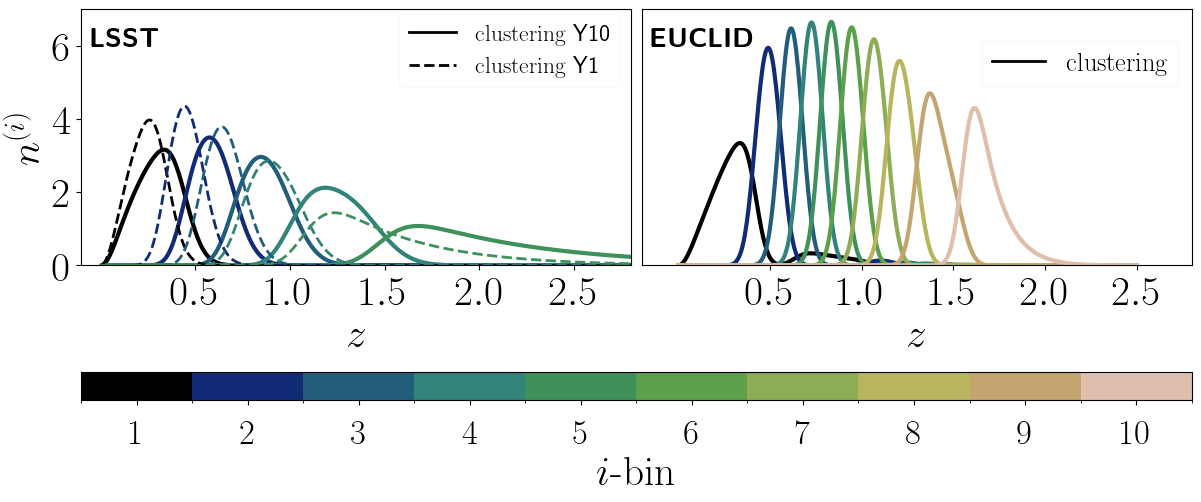

In [13]:
ncols,nrows = 2,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(0.93)*ncols, wspace=0.02, hspace=0.25)
############################################################
nch_y01  = dNdz_densY1_bins['dNdz' ].shape[0]
nch_y10  = dNdz_densY10_bins['dNdz' ].shape[0]
nch_ecl  = dNdz_ecl_bins['dNdz' ].shape[0]
#nch_y01  = nz_y01['dNdz'].shape[0]
#nch_y10  = nz_y10['dNdz'].shape[0]
#nch_euc  = nz_ecl[ 'dNdz'].shape[0]
##
N=10

c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
##
############################################################
# AXIS 00
ax1 = axes[0]
#
yr,yr2 = 'Y1','Y10'
for i in range(nch_y10): ax1.plot(dNdz_densY10_bins['z'], dNdz_densY10_bins['dNdz'][i,:], c=cmap(i), lw=3, ls='solid')
for i in range(nch_y01): ax1.plot(dNdz_densY1_bins['z'], dNdz_densY1_bins['dNdz'][i,:], c=cmap(i), lw=2, ls='dashed')
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$n^{(i)}$", fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)

ax1.set_ylim(0,7)
cyticks = np.arange(0,7,2)
ax1.set_yticks(cyticks)
cxticks = [0.5,1.0,1.5,2.0, 2.5]
ax1.set_xticks(cxticks)
ax1.set_xlim(-0.1,2.8)
ax1.text(x=-0.05, y=6, s=r'$\textbf{LSST}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
                Line2D([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$\textrm{clustering}$ '+'{}'.format(yr2),
                                   r'$\textrm{clustering}$ '+'{}'.format(yr)],
                    bbox_to_anchor=(1.0, 0.65),
                    fontsize=17,ncols=1,loc='lower right',framealpha=0.1)
############################################################
# AXIS 01
ax2 = axes[1]
#
for i in range(nch_ecl):  ax2.plot(dNdz_ecl_bins['z'], dNdz_ecl_bins['dNdz'][i,:] , c=cmap(i), lw=3, ls='solid')
############################################################
ax2.set_xlabel(r"$z$", fontsize =30)    
ax2.tick_params(axis='both', which='major' , labelsize=30)

ax2.set_ylim(0,7)
cyticks = np.arange(0,7,2)
ax2.set_yticks([])
cxticks = [0.5,1.0,1.5,2.0,2.5]
ax2.set_xticks(cxticks)
ax2.set_xlim(-0.2,2.8)

ax2.text(x=-.15, y=6, s=r'$\textbf{EUCLID}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
###########################################################
## COLORBAR ###############################################
###########################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=axes.ravel().tolist(),
                  orientation='horizontal',# extend="both",
                  pad=0.25, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_xticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################
#pathname = "/data/AMARINS/CMBWLxHI-CODES/images/{}.png".format('dNdz_LSST_EUCLID')
#if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
#pathname###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid')]
#
legend_1= ax2.legend(custom_lines, [r'$\textrm{clustering}$'],
                    bbox_to_anchor=(1.0, 0.65),
                    fontsize=19,ncols=1,loc='lower right',framealpha=0.1)
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('dNdz_denmsity_LSST_EUCLID')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname

## KERNEL

In [14]:
def z_hi_survey(hi_survey='LOWZ'):
    if hi_survey.upper()=='LOWZ':
        nu_vec = np.linspace(980,1260,30+1) 
    elif hi_survey.upper()=='HIGHZ':
        nu_vec = np.linspace(350,1050,70+1)
    else:
        raise NameError('No survey named {}'.format(hi_survey))
    return np.flip((nu_HI/nu_vec)-1)


##############################
def kernel_galaxy_lensing_i_dict(camb_params=None, camb_results=None, pars=None,  binning=True, ibin=False, verbose=False, Np=500):#,cut_to_bin=False, ):
    from scipy.interpolate import interp1d
    if verbose: timei = time.time()    
    #dNdz_vec = dNdz_func(zbins=zbins, pars=lens_paparsrs, verbose=False)
    dNdz_vec = dNdz_func(pars=pars , binning=binning, verbose=False)
    #
    chi_z = lambda x: camb_results.comoving_radial_distance(x)    
    fact  = lambda y: 1.5*camb_params.omegam*camb_params.H0**2/c_light/camb_results.hubble_parameter(y)*(1+y)*chi_z(y)
    ####
    #for j in range(dNdz_vec['dNdz'].shape[0]):
    dNdz_intp = interp1d(dNdz_vec['z'], dNdz_vec['dNdz'][ibin,:], kind='cubic')
    ####
    zi_range = np.linspace(pars['z_min'], pars['z_max'],Np)
    gx = np.array([ fact(zi)*integrate.quad(lambda x: dNdz_intp(x)*( (chi_z(x)-chi_z(zi))/chi_z(x) ), zi, pars['z_max'])[0] for zi in zi_range ])
    gx_intp = interp1d(zi_range, gx, kind='cubic')#, fill_value="extrapolate")
    ####
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei))             
    return {'W':gx, 'z':zi_range, 'W_interp':gx_intp, 'bin':ibin}

def kernel_galaxy_lensing_dict(camb_params=None, camb_results=None, pars=None, binning=True, cut_to_bin=False,Np=500, verbose=False):
    c_light = 299792458/1e3
    from scipy.interpolate import interp1d
    if verbose: timei = time.time()        
    #dNdz_vec = dNdz_func(pars=pars , binning=binning, verbose=False)
    dNdz_vec = cxft.dNdz_func(pars=pars, binning=binning,  verbose=False, type_field=pars['field'])
    #
    chi_z = lambda x: camb_results.comoving_radial_distance(x)    
    fact  = lambda y: 1.5*camb_params.omegam*camb_params.H0**2/c_light/camb_results.hubble_parameter(y)*(1+y)*chi_z(y)
    ####
    for j in range(dNdz_vec['dNdz'].shape[0]):
        dNdz_intp = interp1d(dNdz_vec['z'], dNdz_vec['dNdz'][j,:], kind='cubic')
        ####
        zi_range = np.linspace(pars['z_min'], pars['z_max'],Np)
        #if cut_to_bin: zi_range = np.linspace(zbins[j],zbins[j+1],300)
        ####
        igx = np.array([ fact(zi)*integrate.quad(lambda x: dNdz_intp(x)*( (chi_z(x)-chi_z(zi))/chi_z(x) ), zi, pars['z_max'])[0] for zi in zi_range ])
        if not j:
            gx = dcopy(igx)
            zv_range = dcopy(zi_range)
        else:
            gx = np.vstack(( gx,dcopy(igx) ))
            zv_range = np.vstack(( zv_range, dcopy(zi_range) ))
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei))             
    return {'W':gx, 'z':zv_range}  



In [15]:
##############################
def kernel_galaxy_clustering_i_dict(camb_params=None  , camb_results=None, pars=None, cut_to_bin=False, #binning=True,
                                    ibin=0, Np=500, binning=True,
                                    include_rsd=False , include_mb=False , mu_rsd=0 , growth_rate_f=None, 
                                    bias_model ='SQRT', bias_value=1     , path_to_bias_file=None,
                                    mb_model   =False , mb_alpha_value=0 , path_to_mb_file=None  ,
                                    verbose=False):
    c_light = 299792458/1e3
    binning = True
    from scipy.interpolate import interp1d
    if verbose: timei = time.time()     
    #
    z_range  = np.linspace(pars['z_min'], pars['z_max'],Np)
    bias_gc  = 1#get_bias_model(bias_model=bias_model, bias_value=bias_value, pars=pars, path_to_file=path_to_bias_file, z_range=z_range)
    dNdz_vec = cxft.dNdz_func(pars=pars, binning=binning,  verbose=False, type_field=pars['field'])
    #chi_z = lambda x: camb_results.comoving_radial_distance(x)    
    #fact  = lambda y: camb_results.hubble_parameter(y)/c_light
    dNdz_intp = interp1d(dNdz_vec['z'], dNdz_vec['dNdz'][ibin,:], kind='cubic')
    #kernel_gc = np.array([ dNdz_intp(zi)*camb_results.hubble_parameter(zi)/c_light for zi in z_range ])
    kernel_gc = np.array([ dNdz_intp(zi) for zi in z_range ])
    #kernel_gc*=bias_gc
    #
    if include_rsd:
        f_vec = interp1d(camb_results.z_input, camb_results.get_fsigma8()/camb_results.get_sigma8(), kind='cubic')(z_range)
        kernel_gc+=(f_vec*mu_rsd**2)*kernel_gc
    if include_mb:
        MB = magnification_bias(camb_params=camb_params, camb_results=camb_results, pars=pars,
                                slope_s_model=mb_model, z_range=z_range,
                                binning=binning, ibin=ibin, Np=Np, verbose=False)
        kernel_gc+=MB
    kernel_gc_intp = interp1d(z_range, kernel_gc, kind='cubic')
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei))             
    return {'W':kernel_gc, 'z':z_range, 'W_interp':kernel_gc_intp, 'bin':ibin}  


def kernel_galaxy_clustering_dict(camb_params=None  , camb_results=None, pars=None, cut_to_bin=False, #binning=True,
                                  include_rsd=False , include_mb=False , mu_rsd=0 , growth_rate_f=None, 
                                  bias_model ='SQRT', bias_value=1     , path_to_bias_file=None,
                                  mb_model   =False , mb_alpha_value=0 , path_to_mb_file=None  ,Np=500,
                                  verbose=False):
    '''
    RSD:Redshift Spatial Distortion
    MB:Magnification Bias
    mu_rsd: <k,n>=cos(theta)
    growth_rate_f: add in the future the possibility to read a file [z,f(z)]
    pars: parameters of Galaxy survey
    bias_model: constant, LSST, EUCLID, READ [to read a file]
    '''
    c_light = 299792458/1e3
    binning = True
    from scipy.interpolate import interp1d
    if verbose: timei = time.time()     
    #
    z_range  = np.linspace(pars['z_min'], pars['z_max'],Np)
    bias_gc  = get_bias_model(bias_model=bias_model, bias_value=bias_value, pars=pars, path_to_file=path_to_bias_file, z_range=z_range)
    dNdz_vec = cxft.dNdz_func(pars=pars, binning=binning,  verbose=False, type_field=pars['field'])
    #chi_z = lambda x: camb_results.comoving_radial_distance(x)    
    #fact  = lambda y: camb_results.hubble_parameter(y)/c_light
    for j in range(dNdz_vec['dNdz'].shape[0]):
        dNdz_intp = interp1d(dNdz_vec['z'], dNdz_vec['dNdz'][j,:], kind='cubic')
        #igc       = np.array([ dNdz_intp(zi)*camb_results.hubble_parameter(zi)/c_light for zi in z_range ])
        igc       = np.array([ dNdz_intp(zi) for zi in z_range ])
        igc*=bias_gc
        if not j:
            kernel_gc= dcopy(  igc   )
            zv_range = dcopy(z_range )
        else:
            kernel_gc= np.vstack(( kernel_gc, dcopy(igc)     ))
            zv_range = np.vstack((  zv_range, dcopy(z_range) ))        
    if include_rsd:
        f_vec = interp1d(camb_results.z_input, camb_results.get_fsigma8()/camb_results.get_sigma8(), kind='cubic')(z_range)
        kernel_gc+=(f_vec*mu_rsd**2)*kernel_gc
    if include_mb:
        MB = magnification_bias(camb_params=camb_params, camb_results=camb_results, pars=pars,
                                slope_s_model=mb_model, z_range=z_range,
                                binning=binning, ibin=None, Np=Np, verbose=False)
        kernel_gc+=MB
        pass    
    if verbose: print('Total processing time: {0:.2f} seg'.format(time.time()-timei))             
    return {'W':kernel_gc, 'z':zv_range}  

In [16]:
def get_bias_model(bias_model=None, bias_value=1, pars=None, path_to_file=None, z_range=None):
    #[1]
    if bias_model.upper() in ['LSST','EUCLID', 'SQRT']:
        return np.sqrt(1+z_range)
    #[2]    
    elif bias_model.upper() in ['F', 'FLAGSHIP', "FLAG", 'TUTUSAUS', 'TUTUSAUS2020', "FLAG1"]:
        #Euclid: The importance of galaxy clustering and weak lensing cross-correlations within the photometric Euclid survey - I Tutusaus et al (2020)
        coeffs = [1.0, 2.5, 2.8, 1.6] #[A,B,C,D]
        return coeffs[0] + coeffs[1]/(1+ np.exp(-(z_range-coeffs[3])*coeffs[2]))
    #[3] 
    elif bias_model.upper() in ['F2022', 'FLAGSHIP2022', "FLAG2022", 'F2', 'FLAGSHIP2', "FLAG2"]:
        #Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering - F Lepori et al (2022)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [0.5125, 1.377, 0.222, -0.249]
        return nPoly(coeffs)(z_range)
    #[4]    
    elif bias_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zi, bzi = np.loadtxt(path_to_file)            
            return interp1d(zi, bzi, kind='cubic')(z_range)
        except:
            return np.ones_like(z_range)
    #[5]            
    elif  bias_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return bias_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)       
    #[6]        
    else:
        return np.ones_like(z_range)      
                                
def get_slope_s_model(slope_s_model=None, slope_s_value=1, pars=None, path_to_file=None, z_range=None):
    if slope_s_model.upper() in ['F2022', 'FLAGSHIP2022', "FLAG2022", 'F2', 'FLAGSHIP2', "FLAG2",
                                 "LEPORI","LEPORI2022","EUCLID2022","EUCLIDXIX","EXIX","ECXIX"]:
        #Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering - F Lepori et al (2022)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [0.0842,0.0532,0.298,-0.0113]
        return nPoly(coeffs)(z_range)  
    elif slope_s_model.upper() in ["DESHPANDE", "DESHPANDE2020", "DESH", "DESH2020"]:
        #Euclid: The reduced shear approximation and magnification bias for Stage IV cosmic shear experiments - AC Deshpande et al (2020)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [ 0.1547362 ,  0.17613424,  0.04163679,  0.35136411, -0.39927333, 0.19266138, -0.03429751]
        return nPoly(coeffs)(z_range)  
    elif slope_s_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zi, si = np.loadtxt(path_to_file).T            
            return interp1d(zi, si, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)
    elif  slope_s_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return slope_s_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)            
    else:
        return np.ones_like(z_range)                               

    
def magnification_bias(camb_params=None, camb_results=None, pars=None, z_range=None, 
                       slope_s_model=None, slope_s_value=1,  path_to_slope_file=None, 
                       binning=True, ibin=None, Np=500, verbose=False):
    slope_s = get_slope_s_model(slope_s_model=slope_s_model, pars=pars, path_to_file=path_to_slope_file, z_range=z_range)
    if type(ibin)==type(None):
        Wshear = kernel_galaxy_lensing_dict(camb_params=camb_params, Np=Np,
                                            camb_results=camb_results, 
                                            pars=pars,  binning=binning)['W']
    else: 
        Wshear = kernel_galaxy_lensing_i_dict(camb_params=camb_params, camb_results=camb_results, 
                                              Np=Np,pars=pars, ibin=ibin, binning=binning)['W']        
    Wshear*=(5*slope_s-2)
    return Wshear    

In [17]:
def get_charact_luminosity_admensional(L_model=None, L_value=1, pars=None, path_to_file=None, z_range=None):
    #<L>(z)/Lstar(z): Admensional Characteristic Luminosity
    #Euclid: The importance of galaxy clustering and weak lensing cross-correlations within the photometric Euclid survey
    #Eq 15
    #Euclid preparation - VII. Forecast validation for Euclid cosmological probes - Lesgourgues et al 2020
    #Eq 39
    #Euclid preparation: 6x2 pt analysis of Euclid's spectroscopic and photometric data sets - L Paganin et al 2024
    #Eq 13
    if L_model.upper() in ['LESGOURGUES', 'LESGOURGUES2025', 'BLANCHARD', 'BLANCHARD2020', 
                            'EUCLID', 'EUCLID2020','EVII', "ECVII", "EUCLIDVII", "EUCLID2020",
                            'ENLA']:
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [ 0.15682055, -0.95500852,  5.5882817 , -9.60251292,  7.93685053,-2.99044314,  0.4147671 ]
        return nPoly(coeffs)(z_range)      
    elif L_model.upper() in ['READ','FILE']:
        #path_to_file = '../auxiliary/auxiliary/scaledmeanlum-E2Sa.dat'
        try:
            from scipy.interpolate import interp1d
            zc,Lc=np.loadtxt(path_to_file).T
            return interp1d(zc, Lc, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)   
    elif L_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return L_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)           
    else:
        return np.ones_like(z_range)   
    
def get_F_IA_function(F_model=None, F_value=1, pars=None, path_to_file=None, z_range=None,#L_model=None, L_value=1, # A_IA=None, C_IA=None, 
                      beta_IA=None, eta_IA=None, path_to_IA_file=None):
    if F_model.upper() in ['LESGOURGUES',  'LESGOURGUES2025',  'BLANCHARD',  'BLANCHARD2020', 
                           'EUCLID', 'EUCLID2020','EVII', "ECVII", "EUCLIDVII", "EUCLID2020",
                           'ENLA']:
        Lc = get_charact_luminosity_admensional(L_model='EUCLID', pars=pars, z_range=z_range)
        #Lc = get_characteristic_luminosity_admensional(L_model='READ', pars=pars, z_range=z_range, path_to_file='../auxiliary/auxiliary/scaledmeanlum-E2Sa.dat')
        if type(path_to_IA_file)==type(None):
            #C_IA    = 0.0134 if type(   C_IA)==type(None) else C_IA
            #A_IA    = 1.72   if type(   A_IA)==type(None) else A_IA
            eta_IA  = -0.41 if type( eta_IA)==type(None) else eta_IA
            beta_IA = 2.17  if type(beta_IA)==type(None) else beta_IA
        else:
            import yaml
            try:
                F_pars = yaml.safe_load(open(path_to_IA_file))
            except:
                path='../auxiliary/IA_parameters.yaml'
                F_pars = yaml.safe_load(open(path))
            #C_IA    = F_pars[pars['survey']]['eNLA'][   'C_IA']            
            #A_IA    = F_pars[pars['survey']]['eNLA'][   'A_IA']            
            eta_IA  = F_pars[pars['survey']]['eNLA'][ 'eta_IA']            
            beta_IA = F_pars[pars['survey']]['eNLA']['beta_IA']      
        return ( (1+z_range)**eta_IA )*( Lc**beta_IA )
    elif F_model.upper()=='NLA':             
        return np.ones_like(z_range)
    elif F_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zc,Fia=np.loadtxt(path_to_file).T
            return interp1d(zc, Fia, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)   
    elif F_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return F_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)           
    elif F_model.upper() in ['FIT', 'FITTING']: 
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [-1.44658943e-03, -2.30189882e-03,  4.81011268e+00, -4.11111700e+01,
                   1.41315751e+02, -2.49177926e+02,  2.51029131e+02, -1.50252007e+02,
                   5.29125726e+01, -1.01403713e+01,  8.17115026e-01] #Polynomial O(10)
        return nPoly(coeffs)(z_range)         
    else:
        return np.ones_like(z_range)       

In [18]:
Wshear_dict0 = kernel_galaxy_lensing_dict(camb_params=cpars, camb_results=cresults, pars=dens_pars,  binning=True)

In [19]:
#s1, z1 = get_slope_s_model(slope_s_model='LEPORI', pars=dens_pars, path_to_file=None, z_range=zvec), zvec#,slope_s_value=1)
#s2, z2 = get_slope_s_model(slope_s_model='DESHPANDE', pars=dens_pars, path_to_file=None, z_range=zvec), zvec#,slope_s_value=1)
#s2, z2 = get_slope_s_model(slope_s_model='READ', pars=dens_pars, path_to_file='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/EUCLID_deshpande_galaxy_slope.txt', z_range=zvec), zvec#,slope_s_value=1)

In [20]:
'''
magnification_bias(camb_params=cpars, camb_results=cresults, pars=dens_pars,
                       slope_s_model='DESHPANDE', z_range=zvec,
                       binning=True, ibin=None, Np=500, verbose=False)
                       ''';

In [21]:
def get_bias_model(bias_model=None, bias_value=1, pars=None, path_to_file=None, z_range=None):
    #[1]
    if bias_model.upper() in ['LSST','EUCLID', 'SQRT']:
        return np.sqrt(1+z_range)
    #[2]    
    elif bias_model.upper() in ['F', 'FLAGSHIP', "FLAG", 'TUTUSAUS', 'TUTUSAUS2020', "FLAG1"]:
        #Euclid: The importance of galaxy clustering and weak lensing cross-correlations within the photometric Euclid survey - I Tutusaus et al (2020)
        coeffs = [1.0, 2.5, 2.8, 1.6] #[A,B,C,D]
        return coeffs[0] + coeffs[1]/(1+ np.exp(-(z_range-coeffs[3])*coeffs[2]))
    #[3] 
    elif bias_model.upper() in ['F2022', 'FLAGSHIP2022', "FLAG2022", 'F2', 'FLAGSHIP2', "FLAG2"]:
        #Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering - F Lepori et al (2022)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [0.5125, 1.377, 0.222, -0.249]
        return nPoly(coeffs)(z_range)
    #[4]    
    elif bias_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zi, bzi = np.loadtxt(path_to_file)            
            return interp1d(zi, bzi, kind='cubic')(z_range)
        except:
            return np.ones_like(z_range)
    #[5]            
    elif  bias_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return bias_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)       
    #[6]        
    else:
        return np.ones_like(z_range)      
                                
def get_slope_s_model(slope_s_model=None, slope_s_value=1, pars=None, path_to_file=None, z_range=None):
    if slope_s_model.upper() in ['F2022', 'FLAGSHIP2022', "FLAG2022", 'F2', 'FLAGSHIP2', "FLAG2",
                                 "LEPORI","LEPORI2022","EUCLID2022","EUCLIDXIX","EXIX","ECXIX"]:
        #Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering - F Lepori et al (2022)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [0.0842,0.0532,0.298,-0.0113]
        return nPoly(coeffs)(z_range)  
    elif slope_s_model.upper() in ["DESHPANDE", "DESHPANDE2020", "DESH", "DESH2020"]:
        #Euclid: The reduced shear approximation and magnification bias for Stage IV cosmic shear experiments - AC Deshpande et al (2020)
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [ 0.1547362 ,  0.17613424,  0.04163679,  0.35136411, -0.39927333, 0.19266138, -0.03429751]
        return nPoly(coeffs)(z_range)  
    elif slope_s_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zi, si = np.loadtxt(path_to_file).T            
            return interp1d(zi, si, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)
    elif  slope_s_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return slope_s_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)            
    else:
        return np.ones_like(z_range)                               

    
def magnification_bias(camb_params=None, camb_results=None, pars=None, z_range=None, 
                       slope_s_model=None, slope_s_value=1,  path_to_slope_file=None, 
                       binning=True, ibin=None, Np=500, verbose=False):
    slope_s = get_slope_s_model(slope_s_model=slope_s_model, pars=pars, path_to_file=path_to_slope_file, z_range=z_range)
    if type(ibin)==type(None):
        Wshear = kernel_galaxy_lensing_dict(camb_params=camb_params, Np=Np,
                                            camb_results=camb_results, 
                                            pars=pars,  binning=binning)['W']
    else: 
        Wshear = kernel_galaxy_lensing_i_dict(camb_params=camb_params, camb_results=camb_results, 
                                              Np=Np,pars=pars, ibin=ibin, binning=binning)['W']        
    Wshear*=(5*slope_s-2)
    return Wshear    

In [22]:
'''
dt = np.array([ [0.14, 0.758, 0.624, 0.023],
                [0.26, 2.607, 0.921, 0.135],
                [0.39, 4.117, 1.116, 0.248],
                [0.53, 3.837, 1.350, 0.253],
                [0.69, 3.861, 1.539, 0.227],
                [0.84, 3.730, 1.597, 0.280],
                [1.00, 3.000, 1.836, 0.392],
                [1.14, 2.827, 1.854, 0.481],
                [1.30, 1.800, 2.096, 0.603],
                [1.44, 1.078, 2.270, 0.787],
                [1.62, 0.522, 2.481, 1.057],
                [1.78, 0.360, 2.193, 1.138],
                [1.91, 0.251, 2.160, 1.094]]).T

zi,ngi,bi,si = dt

filename='EUCLID_lepori_galaxy_slope.txt'
dt = np.array([zi,si]).T
HEADER='#z(mean) s(z)'
np.savetxt(fname='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/'+filename, X=dt, fmt='%.2f', header=HEADER)

filename='EUCLID_lepori_galaxy_bias.txt'
dt = np.array([zi,bi]).T
HEADER='#z(mean) bias(z)'
np.savetxt(fname='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/'+filename, X=dt, fmt='%.2f', header=HEADER)

filename='EUCLID_lepori_galaxy_number_density.txt'
dt = np.array([zi,ngi]).T
HEADER='#z(mean) ngal(gal/bin/arcmin2)'
np.savetxt(fname='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/'+filename, X=dt, fmt='%.2f', header=HEADER)
''';

In [23]:
z1,s1 = np.loadtxt('/data/AMARINS/LSSxHI-CODES/scripts/auxiliary/EUCLID_lepori_galaxy_slope.txt').T
z2,s2 = np.loadtxt('/data/AMARINS/LSSxHI-CODES/scripts/auxiliary/EUCLID_deshpande_galaxy_slope.txt').T
#z3 = np.hstack([z1,z2[-1]])
#s3 = np.hstack([s1,s2[-1]])
#sint3 = np.poly1d(np.polyfit(z3, s3, 5))(zvec)

#s1, z1 = get_slope_s_model(slope_s_model='LEPORI', pars=dens_pars, path_to_file=None, z_range=zvec), zvec#,slope_s_value=1)
#s2, z2 = get_slope_s_model(slope_s_model='DESHPANDE', pars=dens_pars, path_to_file=None, z_range=zvec), zvec#,slope_s_value=1)
#s2, z2 = get_slope_s_model(slope_s_model='READ', pars=dens_pars, path_to_file='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/EUCLID_deshpande_galaxy_slope.txt', z_range=zvec), zvec#,slope_s_value=1)

In [24]:
def get_charact_luminosity_admensional(L_model=None, L_value=1, pars=None, path_to_file=None, z_range=None):
    #<L>(z)/Lstar(z): Admensional Characteristic Luminosity
    #Euclid: The importance of galaxy clustering and weak lensing cross-correlations within the photometric Euclid survey
    #Eq 15
    #Euclid preparation - VII. Forecast validation for Euclid cosmological probes - Lesgourgues et al 2020
    #Eq 39
    #Euclid preparation: 6x2 pt analysis of Euclid's spectroscopic and photometric data sets - L Paganin et al 2024
    #Eq 13
    if L_model.upper() in ['LESGOURGUES', 'LESGOURGUES2025', 'BLANCHARD', 'BLANCHARD2020', 
                            'EUCLID', 'EUCLID2020','EVII', "ECVII", "EUCLIDVII", "EUCLID2020",
                            'ENLA']:
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [ 0.15682055, -0.95500852,  5.5882817 , -9.60251292,  7.93685053,-2.99044314,  0.4147671 ]
        return nPoly(coeffs)(z_range)      
    elif L_model.upper() in ['READ','FILE']:
        #path_to_file = '../auxiliary/auxiliary/scaledmeanlum-E2Sa.dat'
        try:
            from scipy.interpolate import interp1d
            zc,Lc=np.loadtxt(path_to_file).T
            return interp1d(zc, Lc, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)   
    elif L_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return L_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)           
    else:
        return np.ones_like(z_range)   
    
def get_F_IA_function(F_model=None, F_value=1, pars=None, path_to_file=None, z_range=None,#L_model=None, L_value=1, # A_IA=None, C_IA=None, 
                      beta_IA=None, eta_IA=None, path_to_IA_file=None):
    if F_model.upper() in ['LESGOURGUES',  'LESGOURGUES2025',  'BLANCHARD',  'BLANCHARD2020', 
                           'EUCLID', 'EUCLID2020','EVII', "ECVII", "EUCLIDVII", "EUCLID2020",
                           'ENLA']:
        Lc = get_charact_luminosity_admensional(L_model='EUCLID', pars=pars, z_range=z_range)
        #Lc = get_characteristic_luminosity_admensional(L_model='READ', pars=pars, z_range=z_range, path_to_file='../auxiliary/auxiliary/scaledmeanlum-E2Sa.dat')
        if type(path_to_IA_file)==type(None):
            #C_IA    = 0.0134 if type(   C_IA)==type(None) else C_IA
            #A_IA    = 1.72   if type(   A_IA)==type(None) else A_IA
            eta_IA  = -0.41 if type( eta_IA)==type(None) else eta_IA
            beta_IA = 2.17  if type(beta_IA)==type(None) else beta_IA
        else:
            import yaml
            try:
                F_pars = yaml.safe_load(open(path_to_IA_file))
            except:
                path='../auxiliary/IA_parameters.yaml'
                F_pars = yaml.safe_load(open(path))
            #C_IA    = F_pars[pars['survey']]['eNLA'][   'C_IA']            
            #A_IA    = F_pars[pars['survey']]['eNLA'][   'A_IA']            
            eta_IA  = F_pars[pars['survey']]['eNLA'][ 'eta_IA']            
            beta_IA = F_pars[pars['survey']]['eNLA']['beta_IA']      
        return ( (1+z_range)**eta_IA )*( Lc**beta_IA )
    elif F_model.upper()=='NLA':             
        return np.ones_like(z_range)
    elif F_model.upper() in ['READ','FILE']:
        try:
            from scipy.interpolate import interp1d
            zc,Fia=np.loadtxt(path_to_file).T
            return interp1d(zc, Fia, kind='cubic', fill_value='extrapolate')(z_range)
        except:
            return np.ones_like(z_range)   
    elif F_model.upper() in ['CTE','CONST', 'CONSTANT']:
        try:
            return F_value*np.ones_like(z_range)
        except:
            return np.ones_like(z_range)           
    elif F_model.upper() in ['FIT', 'FITTING']: 
        from numpy.polynomial import Polynomial as nPoly
        coeffs = [-1.44658943e-03, -2.30189882e-03,  4.81011268e+00, -4.11111700e+01,
                   1.41315751e+02, -2.49177926e+02,  2.51029131e+02, -1.50252007e+02,
                   5.29125726e+01, -1.01403713e+01,  8.17115026e-01] #Polynomial O(10)
        return nPoly(coeffs)(z_range)         
    else:
        return np.ones_like(z_range)       

(-0.001, 1.6)

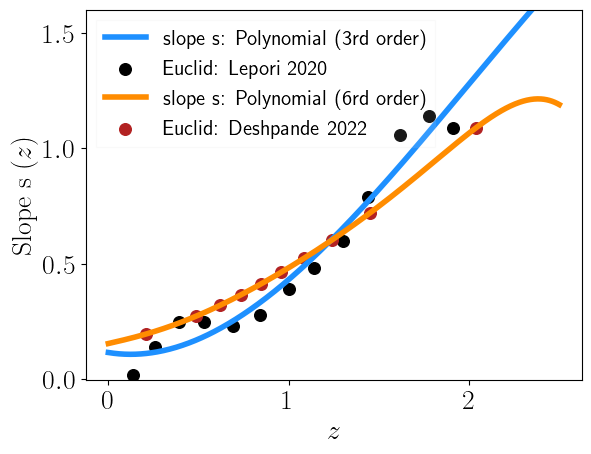

In [25]:
from scipy.interpolate import interp1d
zvec  = np.linspace(dens_pars['z_min'], dens_pars['z_max'],500)
#sext = interp1d(z2, s2, kind='cubic', fill_value='extrapolate')(zvec)
sint1 = np.poly1d(np.polyfit(z1, s1, 3))(zvec)# + 0.1/np.exp(np.poly1d(np.polyfit(z1, s1, 2))(zvec))
sint2 = np.poly1d(np.polyfit(z2, s2, 6))(zvec)
#
plt.plot(zvec, sint1, color='dodgerblue', lw=4, ls='solid', label=r'slope s: Polynomial (3rd order)')
plt.scatter(z1, s1, color='black'    , s=70, label=r'Euclid: Lepori 2020')
#
plt.plot(zvec, sint2, color='darkorange', lw=4, ls='solid', label=r'slope s: Polynomial (6rd order)')
plt.scatter(z2, s2, color='firebrick', s=70, label=r'Euclid: Deshpande 2022')
#
plt.ylabel(r'$\textrm{Slope s } (z)$')
plt.xlabel(r'$z$')
plt.legend(framealpha=0.1, fancybox=False,fontsize=15, )
plt.ylim(-0.001,1.6)
#plt.text(x=1.7, y=0.25, s=r'$\textrm{m}_{\textrm{\normalsize cut}}=24.5$', 
#        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20});

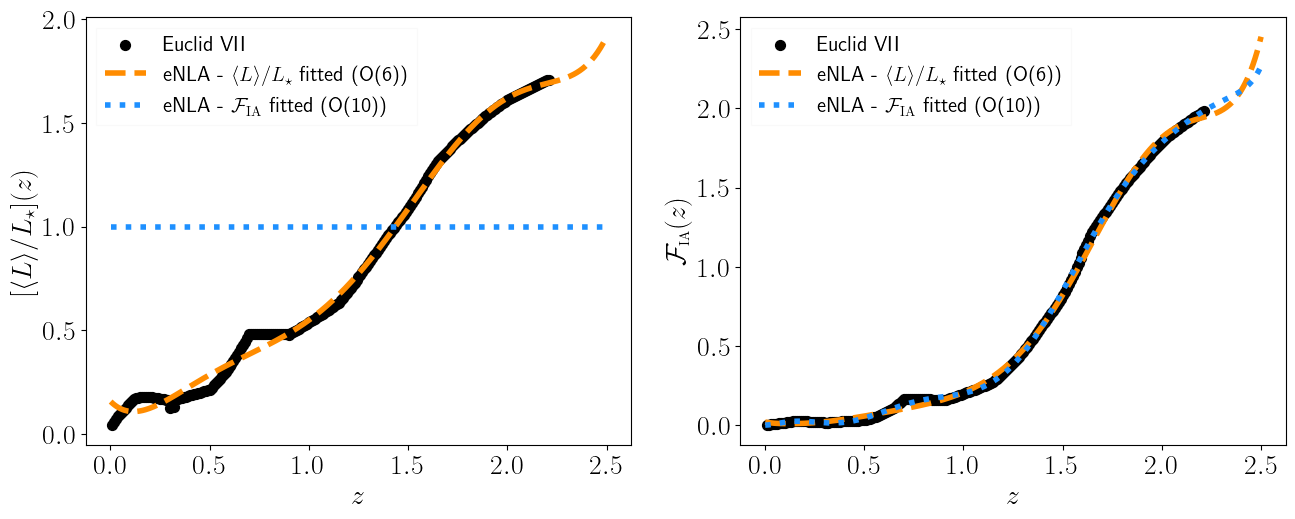

In [26]:
fig   = plt.figure()
grid  = plt.GridSpec(1,2,top=1.,right=2,wspace=0.2, hspace=0.0)
#np.polynomial.Polynomial(np.flip(np.polyfit(zc, Lchar, 6)))
path = '/data/AMARINS/LSSxHI-CODES/scripts/auxiliary/scaledmeanlum-E2Sa.dat'
zc,Lchar=np.loadtxt(path).T
#from scipy.interpolate import interp1d
zvec  = np.linspace(dens_pars['z_min'], dens_pars['z_max'],500)
#Lint1 = interp1d(zc, Lchar, kind='cubic', fill_value='extrapolate')(zvec)
#Lint2 = np.polynomial.Polynomial(np.flip(np.polyfit(zc, Lchar, 6)))(zvec)

L0 = get_charact_luminosity_admensional(L_model='eNLA', pars=dens_pars,z_range=zvec)
L1 = get_charact_luminosity_admensional(L_model='READ', pars=dens_pars,z_range=zvec,path_to_file='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/scaledmeanlum-E2Sa.dat')
ax    = plt.subplot(grid[0,0])   
ax.scatter(zc, Lchar, color='black', s=50, label=r'Euclid VII')
ax.plot(zvec, L0 , color='darkorange', lw=4, ls='dashed', label=r'eNLA - $\langle L\rangle/L_{\star}$ fitted (O(6))')
ax.plot(zvec, L1 , color='dodgerblue', lw=4, ls='dotted', label=r'eNLA - $\mathcal{F}_{\textrm{\normalsize IA}}$ fitted  (O(10))')
ax.set_ylabel(r'$[\langle L\rangle/L_{\star}] (z)$')
ax.set_xlabel(r'$z$')
ax.legend(framealpha=0.1, fancybox=False,fontsize=15, )

ax = plt.subplot(grid[0,1])   
#path='/data1/CROSS/LSSxHI-CODES/scripts/auxiliary/IA_parameters.yaml'
#F_pars = yaml.safe_load(open(path))
etaia  =-0.41 
betaia = 2.17
Fchar  = ( (1+zc  )**etaia )*(Lchar**betaia)
#Fint  = ( (1+zvec)**etaia )*(Lint**betaia)
Fia0 = get_F_IA_function(F_model='eNLA', pars=dens_pars, z_range=zvec)
Fia1 = get_F_IA_function(F_model='fit' , pars=dens_pars, z_range=zvec)

ax.scatter(zc, Fchar, color='black', s=50, label=r'Euclid VII')
ax.plot(zvec, Fia0 , color='darkorange', lw=4, ls='dashed', label=r'eNLA - $\langle L\rangle/L_{\star}$ fitted  (O(6))')
ax.plot(zvec, Fia1 , color='dodgerblue', lw=4, ls='dotted', label=r'eNLA - $\mathcal{F}_{\textrm{\normalsize IA}}$ fitted  (O(10))')
ax.set_ylabel(r'$\mathcal{F}_{\textrm{\normalsize IA}} (z)$')
ax.set_xlabel(r'$z$')
ax.legend(framealpha=0.1, fancybox=False,fontsize=15, );

### ---

In [27]:
gc_pars = cxft.load_survey_parameters(survey_name = 'EUCLID', data_release='Y10', type_field='density')
W_ecl_dict0 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=0)
W_ecl_dict1 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=1, mu_rsd=1)
W_ecl_dict2 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=1, mu_rsd=1,
                                           mb_model='LEPORI', include_mb=1)
#W_ecl_dict2 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
#                                           bias_model='FLAG2', include_rsd=0, Np=500)
#W_ecl_dict2 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
#                                           bias_model='SQRT', include_rsd=1, Np=500)

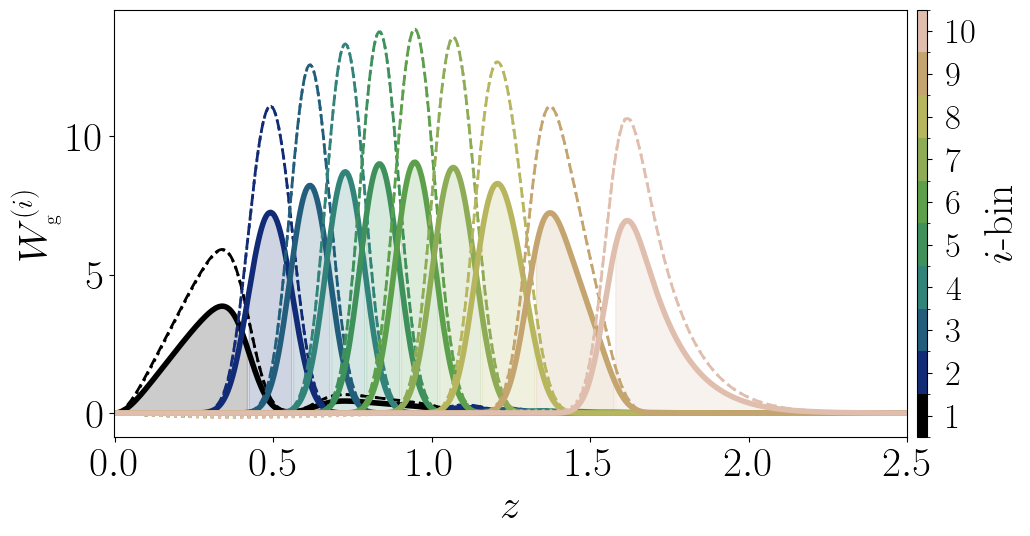

In [28]:
fig, ax1   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.6, wspace=0.02,)     
############################################################
nch_ecl,N  = 10,10
c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i, (zi_min,zi_max) in enumerate(zip(gc_pars['z_edges'][:-1],gc_pars['z_edges'][1:])): 
    x1=W_ecl_dict0['z'][i]
    y1=W_ecl_dict0['W'][i]/Wmax_ecl
    ax1.plot(x1,y1, c=cmap(i), lw=4, ls='solid', label=None)
    ax1.fill_between(x=x1, y1=y1, color= cmap(i),alpha= 0.2,where= (zi_min < x1)&(x1 < zi_max))
    ax1.plot(W_ecl_dict1['z'][i], W_ecl_dict1['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dashed', label=None)
    ax1.plot(W_ecl_dict2['z'][i], W_ecl_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large g}}^{(i)}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
#ax1.set_ylim(-0.02,1.1)
cxticks = [0,0.5,1.0,1.5,2.0,2.5]
ax1.set_xlim(-0.002,2.5)
ax1.set_xticks(cxticks)
###########################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,#.ravel().tolist(),
                  orientation='vertical',# extend="both",
                  pad=0.01, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################

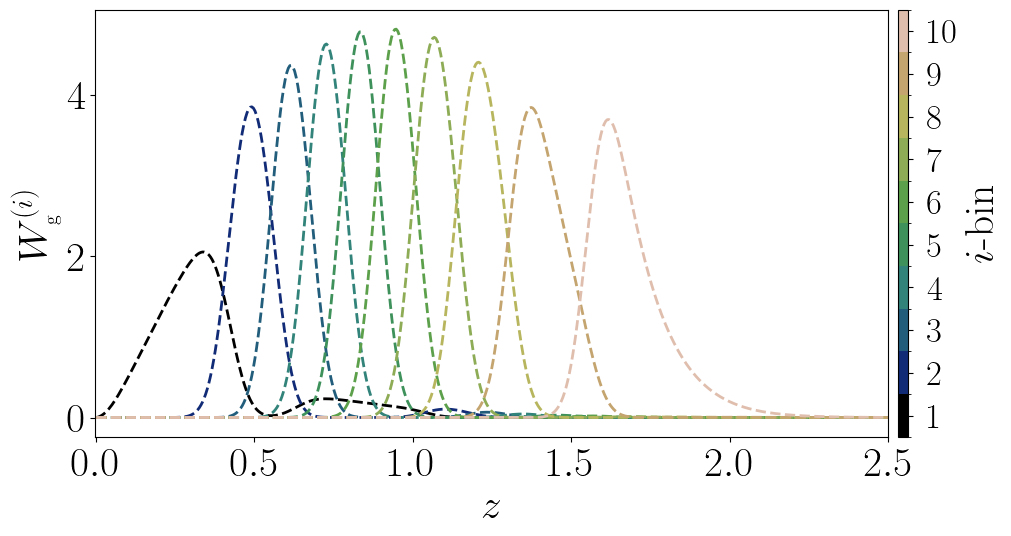

In [29]:
fig, ax1   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.6, wspace=0.02,)     
############################################################
nch_ecl,N  = 10,10
c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i, (zi_min,zi_max) in enumerate(zip(gc_pars['z_edges'][:-1],gc_pars['z_edges'][1:])): 
    ax1.plot(W_ecl_dict1['z'][i], W_ecl_dict1['W'][i]-W_ecl_dict0['W'][i], c=cmap(i), lw=2, ls='dashed', label=None)
    #ax1.plot(W_ecl_dict2['z'][i], W_ecl_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large g}}^{(i)}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
#ax1.set_ylim(-0.02,1.1)
cxticks = [0,0.5,1.0,1.5,2.0,2.5]
ax1.set_xlim(-0.002,2.5)
ax1.set_xticks(cxticks)
###########################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,#.ravel().tolist(),
                  orientation='vertical',# extend="both",
                  pad=0.01, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################

In [30]:
gc_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density')
Wgc     = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                          bias_model='FLAGSHIP', include_rsd=0, Np=500)

In [31]:
dens_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y1', type_field='density')
nz_y01    = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])
dens_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field=dens_pars['field'])
nz_y10    = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])
dens_pars = cxft.load_survey_parameters(survey_name ='EUCLID', data_release='Y10', type_field='density')
nz_ecl    = cxft.dNdz_func(pars=dens_pars, binning=True ,  verbose=False, type_field=dens_pars['field'])

In [32]:
gc_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y1', type_field='density')
W_y01_dict = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=0, Np=500)
gc_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density')
W_y10_dict = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=0, Np=500)
gc_pars = cxft.load_survey_parameters(survey_name = 'EUCLID', data_release='Y10', type_field='density')
W_ecl_dict = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=0, Np=500)

In [ ]:
ncols,nrows = 2,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(0.93)*ncols, wspace=0.02,)
                    
ax1  = axes[0]
ax2  = axes[1]
############################################################
N=10
nch_y01  = nz_y01['dNdz'].shape[0]
nch_y10  = nz_y10['dNdz'].shape[0]
nch_ecl  = nz_ecl['dNdz'].shape[0]
#
c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
###
############################################################
Wmax_y01 = W_y01_dict['W'][:,:].max()
Wmax_y10 = W_y10_dict['W'][:,:].max()
Wmax_ecl = W_ecl_dict['W'][:,:].max()
Wmax_lss = np.amax([Wmax_y10,Wmax_y01])
for i in range(nch_y10): ax1.plot(W_y10_dict['z'][i], W_y10_dict['W'][i]/Wmax_lss, c=cmap(i), lw=3, ls='solid', label=None)
for i in range(nch_y01): ax1.plot(W_y01_dict['z'][i], W_y01_dict['W'][i]/Wmax_lss, c=cmap(i), lw=2, ls='dashed', label=None)
for i in range(nch_ecl): ax2.plot(W_ecl_dict['z'][i], W_ecl_dict['W'][i]/Wmax_ecl, c=cmap(i), lw=3, ls='solid', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{g}}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax2.tick_params(axis='both', which='major' , labelsize=30)
#
ax1.set_ylim(-0.02,1.1)
ax2.set_ylim(-0.02,1.1)
ax2.set_yticks([])

cxticks = [0,0.5,1.0,1.5,2.0,2.5,3.0]
ax1.set_xlim(-0.1,3.2)
ax1.set_xticks(cxticks)
ax2.set_xlim(-0.1,3.2)
ax2.set_xticks(cxticks);
###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
                Line2D([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$\textrm{lensing}$ '+'{}'.format(yr2),
                                   r'$\textrm{lensing}$ '+'{}'.format(yr)],
                    bbox_to_anchor=(1.0, 0.65),
                    fontsize=17,ncols=1,loc='lower right',framealpha=0.1)
############################################################
ax1.text(x=-.05, y=0.95, s=r'$\textbf{LSST}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
ax2.text(x=-.05, y=0.95, s=r'$\textbf{EUCLID}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
###########################################################
## COLORBAR ###############################################
###########################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=axes.ravel().tolist(),
                  orientation='horizontal',# extend="both",
                  pad=0.25, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_xticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('W_density_LSST_EUCLID')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname

In [ ]:
gc_pars = cxft.load_survey_parameters(survey_name = 'EUCLID', data_release='Y10', type_field='density', path_file=path_ecl)
W_ecl_dict0 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                                 bias_model='SQRT', include_rsd=0)
W_ecl_dict1 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                                 bias_model='SQRT', include_rsd=1, mu_rsd=1)
W_ecl_dict2 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                                 bias_model='SQRT', include_rsd=1, mu_rsd=1,
                                                 mb_model='LEPORI', include_mb=1)
#W_ecl_dict2 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
#                                           bias_model='FLAG2', include_rsd=0, Np=500)
#W_ecl_dict2 = kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
#                                           bias_model='SQRT', include_rsd=1, Np=500)

In [ ]:
fig, ax1   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.6, wspace=0.02,)     
############################################################
nch_ecl,N  = 10,10
c    = np.arange(1., nch_ecl + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i, (zi_min,zi_max) in enumerate(zip(gc_pars['z_edges'][:-1],gc_pars['z_edges'][1:])): 
    x1=W_ecl_dict0['z'][i]
    y1=W_ecl_dict0['W'][i]/Wmax_ecl
    ax1.plot(x1,y1, c=cmap(i), lw=4, ls='solid', label=None)
    ax1.fill_between(x=x1, y1=y1, color= cmap(i),alpha= 0.2,where= (zi_min < x1)&(x1 < zi_max))
    ax1.plot(W_ecl_dict1['z'][i], W_ecl_dict1['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dashed', label=None)
    #ax1.plot(W_ecl_dict2['z'][i], W_ecl_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large G}}^{(i)}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax1.set_ylim(-0.0002,0.008) 
cxticks = [0,0.5,1.0,1.5,2.0,2.5]
ax1.set_xlim(-0.002,2.5)
ax1.set_xticks(cxticks)
###########################################################
custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
               Line2D ([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$W_{\textrm{G}}=W_{\textrm{g}}$',
                                    r'$W_{\textrm{G}}=W_{\textrm{g}}+W_{\textrm{RSD}}(\mu=1)$ '],
                    bbox_to_anchor=(1.0, 0.77),
                    fontsize=17,ncols=1,loc='lower right',framealpha=0.1)

ax1.text(x=+0.05, y=0.0074, s=r'$\textbf{EUCLID}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})
############################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,#.ravel().tolist(),
                  orientation='vertical',# extend="both",
                  pad=0.01, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('W_density_EUCLID')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname

In [ ]:
gc_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='density', path_file=path_lsst)
W_lsst_dict0 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=0, )
W_lsst_dict1 = cxft.kernel_galaxy_clustering_dict(camb_params=cpars  , camb_results=cresults, pars=gc_pars,
                                           bias_model='SQRT', include_rsd=1, mu_rsd=1)

In [ ]:
fig, ax1   = plt.subplots(nrows=1, ncols=1)
plt.subplots_adjust(top=1,right=1.6, wspace=0.02,)     
############################################################
nch_ecl,N  = 10,10
c    = np.arange(1., nch_ecl + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i in range(gc_pars['n_tomo_bins']): 
    x1=W_lsst_dict0['z'][i]
    y1=W_lsst_dict0['W'][i]/Wmax_ecl
    ax1.plot(x1,y1, c=cmap(i), lw=4, ls='solid', label=None)
    ax1.fill_between(x=x1, y1=y1, color= cmap(i),alpha= 0.2)#,where= (zi_min < x1)&(x1 < zi_max))
    ax1.plot(W_lsst_dict1['z'][i], W_lsst_dict1['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dashed', label=None)
    #ax1.plot(W_lsst_dict2['z'][i], W_lsst_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large G}}^{(i)}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax1.set_ylim(-0.0002,0.0026) 
cxticks = [0,0.5,1.0,1.5,2.0,2.5,3.0,3.5]
ax1.set_xlim(-0.002,3.5)
ax1.set_xticks(cxticks)
###########################################################

custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
               Line2D ([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$W_{\textrm{G}}=W_{\textrm{g}}$',
                                    r'$W_{\textrm{G}}=W_{\textrm{g}}+W_{\textrm{RSD}}(\mu=1)$ '],
                    bbox_to_anchor=(1.0, 0.77),
                    fontsize=17,ncols=1,loc='lower right',framealpha=0.1)

ax1.text(x=+0.05, y=0.00235, s=r'$\textbf{LSST Y10}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 25})

############################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=ax1,#.ravel().tolist(),
                  orientation='vertical',# extend="both",
                  pad=0.01, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('W_density_LSSTY10')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname

In [ ]:
z_lowz  = cxft.z_hi_survey(hi_survey='LOWZ')
z_highz = cxft.z_hi_survey(hi_survey='HIGHZ')
params_lowz =   {'field':'hi',
                         "freq_min":980, "freq_max":1260, "nchannels":30,
                         "z":z_lowz, 'z_min':z_lowz.min(), 'z_max':z_lowz.max(),
                         'omegaHI_model': None, 'omegaHI':None, 'fit_omegaHI':False, 
                         'biasHI_model' : None, 'biasHI' :None, 'fit_biasHI' :False}
params_highz = {'field':'hi',
                         "freq_min":350, "freq_max":1050, "nchannels":70,
                         "z":z_highz, 'z_min':z_highz.min(), 'z_max':z_highz.max(),
                         'omegaHI_model': None, 'omegaHI':None, 'fit_omegaHI':False, 
                         'biasHI_model' : None, 'biasHI' :None, 'fit_biasHI' :False}

In [ ]:
gl_pars = cxft.load_survey_parameters(survey_name = 'EUCLID', data_release='Y10', type_field='lensing', path_file=path_ecl)
Wl_ecl_dict0  = cxft.kernel_galaxy_lensing_dict(camb_params=cpars, camb_results=cresults, pars=gl_pars, verbose=0, cut_to_bin=False)

gl_pars = cxft.load_survey_parameters(survey_name = 'LSST', data_release='Y10', type_field='lensing', path_file=path_lsst)
gl_pars['bin_range'] = np.asarray(gl_pars['bin_range'])
Wl_lsst_dict0 = cxft.kernel_galaxy_lensing_dict(camb_params=cpars, camb_results=cresults, pars=gl_pars, verbose=0, cut_to_bin=False)

W_lowz_func  = lambda x: cxft.kernel_hi(camb_params=cpars, camb_results=cresults, z=x, zrange=z_lowz, config_dict=params_lowz, replace_inf2nan=True)
W_highz_func = lambda x: cxft.kernel_hi(camb_params=cpars, camb_results=cresults, z=x, zrange=z_highz, config_dict=params_highz, replace_inf2nan=True)

In [ ]:
ncols,nrows = 2,1
fig, axes   = plt.subplots(nrows=nrows, ncols=ncols)
plt.subplots_adjust(top=1*nrows,right=(0.93)*ncols, wspace=0.04,)
                    
ax1  = axes[0]
ax2  = axes[1]
############################################################
N=10
nch_y01  = 5#nz_y01['dNdz'].shape[0]
nch_y10  = 5#nz_y10['dNdz'].shape[0]
nch_ecl  = 10#nz_ecl['dNdz'].shape[0]
#
c    = np.arange(1., nch_y10 + 1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
cmap = plt.get_cmap("gist_earth", N+1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
############################################################
############################################################
#AX1
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i in range(gc_pars['n_tomo_bins']): 
    x1=W_lsst_dict0['z'][i]
    y1=W_lsst_dict0['W'][i]/Wmax_ecl
    ax1.plot(x1,y1, c=cmap(i), lw=4, ls='solid', label=None)
    ax1.fill_between(x=x1, y1=y1, color= cmap(i),alpha= 0.2)#,where= (zi_min < x1)&(x1 < zi_max))
    ax1.plot(W_lsst_dict1['z'][i], W_lsst_dict1['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dashed', label=None)
    #ax1.plot(W_lsst_dict2['z'][i], W_lsst_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax1.set_xlabel(r"$z$"                      , fontsize =30)
ax1.set_ylabel(r"$W_{\textrm{\Large G}}^{(i)}$"             , fontsize =30)    
ax1.tick_params(axis='both', which='major' , labelsize=30)
ax1.set_ylim(-0.0002,0.0026) 
ax2.set_ylim(-0.0002,0.008) 
#ax1.set_ylim(-0.0002,0.0026) 
cxticks = [0.5,1.0,1.5,2.0,2.5,3.0]
ax1.set_xlim(-0.002,3.5)
ax1.set_xticks(cxticks)
ax2.set_yticks([])
#cyticks = [3,6,9,12]
#ax1.set_yticks(cyticks)
############################################################
############################################################
#AX2
Wmax_ecl = 1#W_ecl_dict['W'][:,:].max()
for i in range(10):
    x1=W_ecl_dict0['z'][i]
    y1=W_ecl_dict0['W'][i]/Wmax_ecl
    ax2.plot(x1,y1, c=cmap(i), lw=4, ls='solid', label=None)
    ax2.fill_between(x=x1, y1=y1, color= cmap(i),alpha= 0.2)#,where= (zi_min < x1)&(x1 < zi_max))
    ax2.plot(W_ecl_dict1['z'][i], W_ecl_dict1['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dashed', label=None)
    #ax.plot(W_ecl_dict2['z'][i], W_ecl_dict2['W'][i]/Wmax_ecl, c=cmap(i), lw=2, ls='dotted', label=None)
############################################################
ax2.set_xlabel(r"$z$"                      , fontsize =30)
#ax2.set_ylabel(r"$W_{\textrm{\Large G}}^{(i)}$"             , fontsize =30)    
ax2.tick_params(axis='both', which='major' , labelsize=30)
cxticks = [0,0.5,1.0,1.5,2.0,2.5]
ax2.set_xlim(-0.002,2.5)
ax2.set_xticks(cxticks)

custom_lines = [Line2D([0], [0], color='black', lw=2, ls='solid'),
               Line2D ([0], [0], color='black', lw=2, ls='dashed')]
#
legend_1= ax1.legend(custom_lines, [r'$W^{(i)}_{\textrm{\normalsize G}}=W^{(i)}_{\textrm{\normalsize g}}$',
                                    r'$W^{(i)}_{\textrm{\normalsize G}}=W^{(i)}_{\textrm{\normalsize g}}+W^{(i)}_{\textrm{\normalsize RSD}}(\mu=1)$ '],
                    bbox_to_anchor=(1.7, 0.97),
                    fontsize=17,ncols=2,loc='lower right',framealpha=0.1)
############################################################
ax1.text(x=+.05, y=0.00235, s=r'$\textbf{LSST Y10}$', 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
ax2.text(x=+.05, y=0.0072, s=r'$\textbf{EUCLID}$', 
       fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 20})
###########################################################
## COLORBAR ###############################################
###########################################################
fig.subplots_adjust()
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar=fig.colorbar(sm, ax=axes.ravel().tolist(),
                  orientation='horizontal',# extend="both",
                  pad=0.25, aspect=40, ticks=cticks+0.5)
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_xticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
###########################################################
###########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('W_density_LSSTY10_EUCLID')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname

In [ ]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=0.9,right=1.3, wspace=0.03)
ax  = plt.subplot(grid[0,0])
#
N=10
nch  = 10#W_dict['W'].shape[0]
cmap = plt.get_cmap("gist_earth", N+1)
#
c    = np.arange(0, nch+1)
norm = mpl.colors.BoundaryNorm(np.arange(1, N+2,1),N)
sm   = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([]) 

zv = np.linspace(0,4,300)
wmax = Wg_lsst_dict0['W'][:,:].max()
for i in range(5): plt.plot(Wg_lsst_dict0['z'][i,:],Wg_lsst_dict0['W'][i,:]/wmax, color=cmap(i), ls='dashed', lw=3)
wmax = Wg_ecl_dict0['W'][:,:].max()
for i in range(10): plt.plot(Wg_ecl_dict0['z'][i,:],Wg_ecl_dict0['W'][i,:]/wmax, color=cmap(i), ls='solid', lw=2)
#ax.plot(zv, Wgamma/wmax, c='forestgreen', ls='dotted', lw=5)
########
zv = np.linspace(0,4,10000)
Wlowz = np.array([ W_lowz_func(izv) for izv in zv ])
ax.scatter(zv, Wlowz/Wlowz.max(), s=1, c='red')
########
zv = np.linspace(0,4,10000)
Whighz = np.array([ W_highz_func(izv) for izv in zv ])
ax.scatter(zv, Whighz/Whighz.max(), s=1, c='blue')
############################################################
ax.set_xlabel(r"$z$"                      , fontsize =25)
ax.set_ylabel(r"$W$"                      , fontsize =25)
ax.tick_params(axis='both', which='major' , labelsize=25)
ax.set_ylabel(r"$W{\textrm{\normalsize G}} (z)\ |\ W_{\textrm{\small HI}} (z)\ {\Large [\textrm{mK}]}$", fontsize=25)  
ax.set_ylim(0.1,1.2)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(0.1,3.6)

cxticks = [0.2, 0.5, 1.0, 2.0, 3.0]
ax.set_xticks(cxticks, [r'${}$'.format(s) for s in cxticks])

cyticks = [0.1,0.2, 0.5,1]
ax.set_yticks(cyticks, [r'${:.1f}$'.format(z) for z in cyticks]);
###########################################################
font_dict['color']='#0000ff';font_dict['size']=20
ax.text(x=1.7, y=0.23,s=r'$\textbf{HIGH-Z}$', fontdict=font_dict,rotation=-44)

font_dict['color']='#ff0000';font_dict['size']=20
ax.text(x=0.13, y=0.81,s=r'$\textbf{LOW-Z}$', fontdict=font_dict,rotation=-4)

font_dict['color']='#000000';font_dict['size']=20
ax.text(x=0.12, y=0.26,s=r'$\textbf{LSST Y10}$', fontdict=font_dict,rotation=50)

font_dict['color']='#000000';font_dict['size']=20
ax.text(x=0.145, y=0.12,s=r'$\textbf{EUCLID}$', fontdict=font_dict,rotation=52)
###########################################################
cticks = np.arange(1, N+1,1)#np.linspace(1, len(c)+1, len(c), dtype=np.int8)
cbar   = fig.colorbar(sm,ax=ax, pad=0.01, aspect=30, ticks=cticks+0.5)
#cbar.locator = MaxNLocator(nbins=N)
#cbar.update_ticks()
cbar.set_label(label=r'$i\textrm{-bin}$',size=30)#,weight='bold')
cticks = np.array([r'${}$'.format(i) for i in cticks])
cbar.ax.set_yticklabels(cticks)
cbar.ax.tick_params(labelsize=25, pad=10);
##########################################################
pathname = "/data/AMARINS/LSSxHI-CODES/images/{}.png".format('Wz_HI_LSST_EUCLID')
if 1: plt.savefig(pathname, dpi=100, bbox_inches='tight');
pathname